<a href="https://colab.research.google.com/github/profrash-tech/biometrics-hub-notebooks/blob/main/NB4_Supervised_ML_Regression_STUDENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4 · Supervised Machine Learning: Predicting Systolic Blood Pressure

**About 360 minutes** · Course: *Data Science and Machine Learning with a Framingham teaching dataset*

*Prerequisites: Notebooks 1-3. The primary model uses 11 predictors and excludes `diaBP`, `prevalentHyp` and `TenYearCHD`; `BPMeds` appears only in a labelled sensitivity analysis.*

### 🎯 Learning objectives
After this notebook you will be able to:
- frame sysBP estimation as supervised regression and choose metrics (RMSE, MAE, R squared)
- build leak-free scikit-learn Pipelines and ColumnTransformers
- establish a baseline before trusting a complex model
- compare linear, regularised, forest and boosting models with cross-validation
- tune hyper-parameters on training data and choose a model on validation data
- explain predictions with permutation importance and error analysis, including subgroups
- evaluate the chosen model once on the test set and report it honestly

### ❓ Research questions addressed here
- **RQ9.** Which predictors contribute most to explaining variation in systolic blood pressure?
- **RQ10.** Can systolic blood pressure be estimated from selected demographic and clinical predictors?
- **RQ11.** How well do linear and non-linear regression models estimate systolic blood pressure?
- **RQ12.** Does the model make larger errors for particular groups?

### 🧭 How to use this notebook
- Run cells from **top to bottom** with **Shift + Enter**. Do not skip cells.
- Each new idea gets its own short cell: **first** a plain-language explanation, **then** the code, **then** a
  line-by-line walk-through of what each line does. Read all three before moving on.
- Every part follows the same seven-step rhythm:
  **📘 LEARN** (idea) → **▶️ SEE** (worked code) → **✏️ TRY** (you code) → **🔍 ANALYZE** (inspect results) →
  **💬 INTERPRET** (connect to the research question) → **✅ CHECK** (test yourself) → **🔬 RESEARCH** (go further).
- Cells marked `# TODO` are for you. Replace the placeholder (`None`) with your own code.
  Unfinished cells still run, so the notebook never stops because of a blank.
- Written answers go between the triple quotes of the `answer_...` variable. Knowledge-check answers are a
  single letter.
- After each exercise there is a one-line **🎯 check** cell. Run it to see ✅ or ❌ and a hint. It never shows
  the answer and never stops the notebook. The **📊 progress** cell near the end adds everything up.
- Exercises are self-contained: they use only objects created in the guided cells above them, never your own
  answers from other exercises.
- Solutions are **not** in this notebook. Your instructor decides when to release them.

**🎯 Course checker.** Click ▶ once on the next cell. It loads the small helper that tells you whether each exercise is right (✅ or ❌) and keeps a progress count. There is nothing to read or change in it. If you are offline, the notebook still works; only the feedback is unavailable.

In [1]:
#@title ⚙️ Course checker: click ▶ once, nothing to read here { display-mode: "form" }
import os, urllib.request
CHECKER_URL = "https://raw.githubusercontent.com/festusoladayoonline-debug/biometrics-hub-checker/main/hub_check.py"
try:                                    # get the newest checker; use the local copy if offline
    _data = urllib.request.urlopen(CHECKER_URL, timeout=10).read()
    open("hub_check.py", "wb").write(_data)
except Exception:
    pass
try:
    from hub_check import check, progress
    print("Course checker ready.")
except Exception:                       # the notebook still works without feedback
    def check(ex): print("Checker not available (offline?). Your notebook still works; ask your teacher.")
    def progress(n=None): print("Checker not available.")
    print("Course checker could not be loaded.")

Course checker ready.


### ⚠️ Read this before analysing anything
- The data file is a **commonly circulated teaching subset** associated with the Framingham Heart Study. It is
  **not** the complete original cohort and not an official, representative clinical dataset. Its provenance and
  sampling are not documented in the file.
- The data are **observational**. Associations found here do **not** establish causation.
- Missing values and a rare outcome (about 15% recorded CHD) affect every analysis you will do.
- Any prediction exercise is **educational**. It is not a clinically validated risk tool, and nothing here is
  individual medical advice.

### ⚙️ Setup
Run the next two cells. The first brings in the tools (called *libraries*) and fixes the random seed so your results can be reproduced; the second finds and loads the data **without changing it**.

### ▶️ SEE · Load the tools

The first cell loads the libraries this notebook uses.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42                      # one fixed seed for the whole course
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


**🔎 What each line does**

- `import numpy as np`  →  loads NumPy, the library for fast number arrays, and gives it the short name `np`
- `import pandas as pd`  →  loads pandas, the library for data tables (called DataFrames), short name `pd`
- `import matplotlib.pyplot as plt`  →  loads Matplotlib's plotting tools, short name `plt`
- `import seaborn as sns`  →  loads seaborn, which draws nicer statistical charts on top of Matplotlib
- `SEED = 42`  →  stores the number 42 in a variable called SEED; every random step in the course uses it, so results repeat exactly
- `np.random.seed(SEED)`  →  tells NumPy's random-number generator to start from that seed
- `sns.set_theme`  →  chooses a clean chart style for every figure
- `pd.set_option("display.precision", 3)`  →  shows numbers with 3 decimals when pandas prints a table
- `pd.set_option("display.max_columns", 30)`  →  lets pandas show up to 30 columns instead of hiding some
- `print("pandas"`  →  prints the library versions so you can tell someone exactly what you used

**👀 What you should see:** one line such as `pandas 2.x | numpy 1.x` and no error message.

### ▶️ SEE · Load the data

The second cell finds the data file and reads it into a table.

In [3]:
from pathlib import Path

CANDIDATES = [Path("data/framingham.csv"), Path("../data/framingham.csv"), Path("framingham.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    try:                                   # Google Colab: upload the file when asked
        from google.colab import files
        files.upload()
        DATA_PATH = Path("framingham.csv")
    except ImportError:
        raise FileNotFoundError("Put framingham.csv in a folder called data/ next to the notebooks.")

df_raw = pd.read_csv(DATA_PATH)            # "NA" text in the file becomes NaN
df = df_raw.copy()                         # work on a copy; df_raw stays untouched
print("Loaded", DATA_PATH, "->", df.shape[0], "rows x", df.shape[1], "columns")

Saving framingham.csv to framingham.csv
Loaded framingham.csv -> 4240 rows x 16 columns


**🔎 What each line does**

- `from pathlib import Path`  →  brings in a tool for working with file locations
- `CANDIDATES = [`  →  a list of places where the data file might be; the code tries them in order
- `DATA_PATH = next(`  →  picks the first location where the file really exists (or `None` if it is nowhere)
- `if DATA_PATH is None:`  →  only if the file was not found, try the Google Colab upload instead
- `files.upload()`  →  in Colab this opens a window to upload framingham.csv
- `raise FileNotFoundError`  →  stops with a clear message if the file cannot be found anywhere
- `df_raw = pd.read_csv(DATA_PATH)`  →  reads the CSV file into a pandas table called `df_raw`; the text NA becomes a missing value (NaN)
- `df = df_raw.copy()`  →  makes a separate working copy called `df`, so the untouched original is always there
- `print("Loaded"`  →  prints how many rows and columns were loaded: expect 4240 rows x 16 columns

**👀 What you should see:** `Loaded data/framingham.csv -> 4240 rows x 16 columns`.

### ▶️ SEE · More tools for machine learning

These imports bring in the scikit-learn tools used in this notebook. Each is explained where it is first used.

In [4]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
print('machine-learning tools (1/2) ready')

machine-learning tools (1/2) ready


**🔎 What each line does**

- `model_selection`  →  splitting rows and cross-validation
- `ColumnTransformer`  →  different steps for different columns
- `Pipeline`  →  chains steps into one model
- `SimpleImputer`  →  fills gaps with learned values
- `OneHotEncoder, StandardScaler`  →  turn categories into 0/1 columns; rescale numbers

**👀 What you should see:** `machine-learning tools (1/2) ready`.

### ▶️ SEE · Models and metrics

The second group: the models and the scores.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
print('machine-learning tools (2/2) ready')

machine-learning tools (2/2) ready


**🔎 What each line does**

- `DummyRegressor`  →  the always-predict-the-mean baseline
- `LinearRegression, Ridge, Lasso`  →  linear models, two with penalties
- `RandomForestRegressor, HistGradientBoostingRegressor`  →  two tree-based models
- `permutation_importance`  →  shuffle-based importance
- `mean_squared_error`  →  the metric functions

**👀 What you should see:** `machine-learning tools (2/2) ready`.

---
## Part 1 · The regression task, the split and the metrics
*About 35 min · Research question(s): RQ10*

### 📘 LEARN · Supervised regression in one picture

**Supervised learning** means learning from examples where the answer is known. **Regression** predicts a *number*. We learn a function that takes predictors **X** and returns an estimate of **y** (here `sysBP`, in mmHg).
- **Training rows** fit the model. **Validation rows** choose between models. **Test rows** give one final honest score.
- **X** has the 11 primary predictors. We exclude `diaBP` (a second reading of blood pressure), `prevalentHyp` (may be defined from blood pressure) and `TenYearCHD` (a later outcome).

**📖 New words**

- **supervised learning**: learning from examples with known answers
- **features**: the predictor columns (X)
- **target**: the number we predict (y)
- **RMSE**: root mean squared error: typical error in mmHg, big misses count more
- **MAE**: mean absolute error: average miss in mmHg
- **R squared**: share of variation explained; 0 = no better than always predicting the mean

### ▶️ SEE · The three metrics on a tiny example

Three people: real blood pressure and a model's guess.

In [6]:
y_true = [120, 130, 150]
y_pred = [125, 128, 140]
print("MAE ", mean_absolute_error(y_true, y_pred))
print("RMSE", round(mean_squared_error(y_true, y_pred) ** 0.5, 2))

MAE  5.666666666666667
RMSE 6.56


**👀 What you should see:** `MAE 5.666...` and `RMSE 6.4`: RMSE is larger because the miss of 10 counts extra.

### ▶️ SEE · R squared on the same example

1.0 is perfect; 0 is as good as always guessing the mean.

In [7]:
print(round(r2_score(y_true, y_pred), 3))

0.724


**👀 What you should see:** about `0.82`.

### ▶️ SEE · Step 1: the master split (same as Notebook 3)

Seed 42, 70/15/15, stratified on `TenYearCHD`. First the test set, then training and validation.

In [8]:
train_val, test = train_test_split(df, test_size=0.15, stratify=df["TenYearCHD"], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.15 / 0.85,
                              stratify=train_val["TenYearCHD"], random_state=SEED)
print(len(train), len(val), len(test))

2968 636 636


**🔎 What each line does**

- `train_val, test = train_test_split(`  →  sets 15% of the rows aside as the test set
- `stratify=df["TenYearCHD"]`  →  keeps the CHD share equal in each part
- `train, val = train_test_split(train_val`  →  splits the remaining 85% into training and validation
- `test_size=0.15 / 0.85`  →  so validation is 15% of the whole file
- `random_state=SEED`  →  seed 42: the same split every time

**👀 What you should see:** `2968 636 636`.

### ▶️ SEE · Step 2: choose the features and the target

We name the columns once; the lists are reused later. `NUM`, `CAT` and `BIN` say how each feature will be preprocessed.

In [9]:
FEATURES = ["male", "age", "education", "currentSmoker", "cigsPerDay", "diabetes", "prevalentStroke",
            "totChol", "BMI", "heartRate", "glucose"]
TARGET = "sysBP"
NUM = ["age", "cigsPerDay", "totChol", "BMI", "heartRate", "glucose"]
CAT = ["education"]
BIN = ["male", "currentSmoker", "diabetes", "prevalentStroke"]

**🔎 What each line does**

- `FEATURES = [`  →  the 11 allowed predictors
- `TARGET = "sysBP"`  →  the number to predict
- `NUM = [`  →  numeric columns (will be filled with the median and scaled)
- `CAT = ["education"]`  →  a category column (will be one-hot encoded)
- `BIN = [`  →  yes/no columns (filled with the most frequent value)

**👀 What you should see:** nothing printed.

### ▶️ SEE · Step 3: the matrices

By convention `X` holds the predictors and `y` the target. The test rows are set aside and not touched until Part 9.

In [10]:
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
print(X_train.shape, X_val.shape)

(2968, 11) (636, 11)


**👀 What you should see:** `(2968, 11) (636, 11)`.

### ✏️ TRY · Exercise 4.1 · Check the matrices

Store `n_features` (number of columns of `X_train`), `n_train`, `n_val` and `target_in_features` (is the text `"sysBP"` among the columns of `X_train`? it must be False).

**Result variable(s):** `n_features`, `n_train`, `n_val`, `target_in_features`

In [11]:
# [Exercise 4.1]
n_features = X_train.shape[1]          # X_train.shape[1]
n_train =   len(X_train)           # len(X_train)
n_val = len(X_val)               # len(X_val)
target_in_features = "sysBP" in X_train.columns  # "sysBP" in X_train.columns
print(n_features, n_train, n_val, target_in_features)

11 2968 636 False


In [ ]:
check("4.1")   # 🎯 run this cell to check your answer

✅ `n_features`: correct!
✅ `n_train`: correct!
✅ `n_val`: correct!
✅ `target_in_features`: correct!


### 🔍 ANALYZE · Question 4.1 · Why validation and test?

Why do we need both? What goes wrong if we try five models and report the best score on the test set? Start: 'The validation set is for ..., the test set is for ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [12]:
# [Question 4.1]
answer_4_1 = """ The validation set is for comparing models and selecting the best one, while the test set is for evaluating the final selected model on unseen data.
 If we try five models and choose the one with the highest test score, we are indirectly using the test set to train or select the model.
This can lead to overfitting and an overly optimistic performance estimate that may not reflect how well the model performs on new data.

"""

In [13]:
check("Q4.1")   # 🎯 run this cell to check your answer

📝 answer saved (76 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.1

Which metric is in the same units as the target (mmHg) and punishes big misses more?

- **A.** RMSE
- **B.** R squared
- **C.** The p-value
- **D.** The seed

In [14]:
# [Knowledge check 4.1]
kc_4_1 = "A"   # type "A", "B", "C" or "D"

In [15]:
check("K4.1")   # 🎯 run this cell to check your answer

✅ `kc_4_1`: correct!


---
## Part 2 · Leak-free preprocessing with pipelines
*About 40 min · Research question(s): RQ10*

### 📘 LEARN · Pipelines keep the training-only rule automatic

A scikit-learn **Pipeline** chains preprocessing and a model. When you call `.fit(X_train, y_train)`, every step learns **only** from `X_train`; `.predict(X_new)` re-uses what was learned. Inside cross-validation the pipeline is re-fitted on each training part, so held-out rows never influence the imputer or the scaler.
We build it from three small tools, each shown alone first:
- **SimpleImputer**: fills gaps with a typical value learned from training.
- **StandardScaler**: rescales a column to mean 0 and spread 1 (so penalties treat columns fairly).
- **OneHotEncoder**: turns a category such as education (1-4) into one 0/1 column per level.

**📖 New words**

- **pipeline**: a chain of steps that run in order
- **one-hot encoding**: one 0/1 column per category level
- **scaling**: putting columns on a comparable scale
- **ColumnTransformer**: applies different steps to different columns

### ▶️ SEE · An imputer on a tiny table

The median of [100, 120, missing, 140] is 120, so the gap becomes 120.

In [16]:
tiny = pd.DataFrame({"sbp": [100, 120, np.nan, 140]})
print(SimpleImputer(strategy="median").fit_transform(tiny).ravel())

[100. 120. 120. 140.]


**👀 What you should see:** `[100. 120. 120. 140.]`.

### ▶️ SEE · A scaler on a tiny table

After scaling the values have mean 0 and standard deviation 1.

In [17]:
print(StandardScaler().fit_transform(tiny.fillna(120)).ravel().round(2))

[-1.41  0.    0.    1.41]


**👀 What you should see:** about `[-1.41  0.    0.    1.41]`.

### ▶️ SEE · One-hot encoding on a tiny table

Three people with education 1, 2, 1 become two columns.

In [18]:
edu = pd.DataFrame({"education": [1, 2, 1]})
print(OneHotEncoder().fit_transform(edu).toarray())

[[1. 0.]
 [0. 1.]
 [1. 0.]]


**👀 What you should see:** `[[1. 0.] [0. 1.] [1. 0.]]`: column 1 means level 1, column 2 means level 2.

### ▶️ SEE · Combine the steps for each column group

A `ColumnTransformer` applies one recipe to the numeric columns, another to the category and another to the yes/no columns. `add_indicator=True` adds a 0/1 column marking where numeric values were missing.

In [19]:
def make_preprocessor(scale=True):
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
    ])

**🔎 What each line does**

- `def make_preprocessor(scale=True):`  →  a function that builds the preprocessing block; `scale=False` skips scaling (trees do not need it)
- `num_steps = [`  →  the numeric recipe starts with median imputation plus missing-value indicators
- `num_steps.append(("scale"`  →  adds scaling when asked
- `("num", Pipeline(num_steps), NUM)`  →  apply the numeric recipe to the NUM columns
- `("cat", Pipeline(`  →  category recipe: most frequent value, then one-hot
- `handle_unknown="ignore"`  →  an unseen level later becomes all zeros instead of an error
- `("bin", SimpleImputer`  →  yes/no columns: just fill gaps with the most frequent value

**👀 What you should see:** nothing printed; the function is defined.

### ▶️ SEE · Attach a model and an evaluation helper

`make_model` puts the preprocessing and a model into one Pipeline. `evaluate` returns the three metrics for any fitted model.

In [20]:
def make_model(estimator, scale=True):
    return Pipeline([("prep", make_preprocessor(scale)), ("model", estimator)])

def evaluate(model, X, y):
    pred = model.predict(X)
    return {"RMSE": mean_squared_error(y, pred) ** 0.5, "MAE": mean_absolute_error(y, pred), "R2": r2_score(y, pred)}

**🔎 What each line does**

- `def make_model(estimator, scale=True):`  →  takes any model and returns preprocessing + model as one object
- `Pipeline([("prep"`  →  step 1: preprocessing; step 2: the model
- `def evaluate(model, X, y):`  →  scores a fitted model on rows X with true answers y
- `pred = model.predict(X)`  →  the model's predictions
- `return {"RMSE"`  →  the three metrics in a dictionary

**👀 What you should see:** nothing printed; both functions are defined.

`add_indicator=True` adds a 0/1 column for each numeric variable that had gaps *in the training data* (the pipeline version of the `glucose_missing` flag from Notebook 3).

### ▶️ SEE · A baseline first

A baseline ignores the predictors and always predicts the training mean. Any useful model must beat it.

In [21]:
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
print({k: round(v, 3) for k, v in evaluate(baseline, X_val, y_val).items()})

{'RMSE': 21.359, 'MAE': 16.258, 'R2': -0.001}


**👀 What you should see:** RMSE about `21.4` and R squared about `0.0` (slightly negative).

### ▶️ SEE · The linear-regression pipeline

Preprocessing + linear regression, fitted on training rows only.

In [22]:
linear = make_model(LinearRegression()).fit(X_train, y_train)
print({k: round(v, 3) for k, v in evaluate(linear, X_val, y_val).items()})

{'RMSE': 18.914, 'MAE': 14.351, 'R2': 0.215}


**👀 What you should see:** RMSE about `18.9` and R squared about `0.22`.

### ✏️ TRY · Exercise 4.2 · Always start with a baseline

Fit `DummyRegressor(strategy="mean")` on the training data as `baseline_exercise`, then store its validation RMSE and R squared in `baseline_rmse` and `baseline_r2` (use `evaluate`).

**Result variable(s):** `baseline_rmse`, `baseline_r2`

In [23]:
# [Exercise 4.2]
baseline_exercise = DummyRegressor(strategy="mean").fit(X_train, y_train)   # DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_rmse =evaluate(baseline_exercise, X_val, y_val)["RMSE"]       # evaluate(baseline_exercise, X_val, y_val)["RMSE"]
baseline_r2 = evaluate(baseline_exercise, X_val, y_val)["R2"]         # evaluate(baseline_exercise, X_val, y_val)["R2"]
print(baseline_rmse, baseline_r2)

21.358705918204926 -0.0013465674884685086


In [24]:
check("4.2")   # 🎯 run this cell to check your answer

✅ `baseline_rmse`: correct!
✅ `baseline_r2`: correct!


### ✏️ TRY · Exercise 4.3 · The linear-regression pipeline

Build `linear_pipe = make_model(LinearRegression())`, fit it on the training data, and store its validation `linear_rmse` and `linear_r2`.

**Result variable(s):** `linear_rmse`, `linear_r2`

In [25]:
# [Exercise 4.3]
linear_pipe = make_model(LinearRegression()).fit(X_train, y_train)   # make_model(LinearRegression()).fit(X_train, y_train)
linear_rmse = evaluate(linear_pipe, X_val, y_val)["RMSE"]  # evaluate(linear_pipe, X_val, y_val)["RMSE"]
linear_r2 =evaluate(linear_pipe, X_val, y_val)["R2"]    # evaluate(linear_pipe, X_val, y_val)["R2"]
print(linear_rmse, linear_r2)

18.913876055805964 0.21477228704096452


In [26]:
check("4.3")   # 🎯 run this cell to check your answer

✅ `linear_rmse`: correct!
✅ `linear_r2`: correct!


### 💬 INTERPRET · Question 4.2 · Reading the baseline

Compare the linear model with the baseline. How much does it reduce the typical error, and does R squared of about 0.2 make it a good model for sysBP? Start: 'The linear model lowers the error from ... to ..., but ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [27]:
# [Question 4.2]
answer_4_2 = """ The linear model lowers the error from 16.258 to 14.351 (MAE), reducing the typical prediction error by approximately 1.91 units (11.7%), but the improvement is modest.
 An R² of 0.215 means the model explains only 21.5% of the variation in systolic blood pressure, suggesting that it has limited predictive ability and is not yet a strong model for sysBP.

"""

In [28]:
check("Q4.2")   # 🎯 run this cell to check your answer

📝 answer saved (59 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.2

Why put the imputer **inside** the pipeline rather than imputing the whole file first?

- **A.** Each fit (and each cross-validation fold) then learns the imputation values only from its own training rows
- **B.** It makes the model faster
- **C.** pandas cannot impute
- **D.** It removes outliers

In [29]:
# [Knowledge check 4.2]
kc_4_2 = "A"   # type "A", "B", "C" or "D"

In [30]:
check("K4.2")   # 🎯 run this cell to check your answer

✅ `kc_4_2`: correct!


---
## Part 3 · Cross-validation on the training data
*About 30 min · Research question(s): RQ11*

### 📘 LEARN · Why cross-validate?

One validation score depends on which rows happened to land in validation. **k-fold cross-validation (CV)** splits the *training* rows into k parts; each part is held out once while the model is fitted on the other k - 1, then the k scores are averaged (their spread shows the uncertainty).
We use **5 folds, shuffled, seed 42**. CV uses training rows only; validation and test stay out of it.

**📖 New words**

- **fold**: one of the k parts
- **cross-validation**: repeated hold-out scoring across k folds

### ▶️ SEE · Step 1: the folds

`KFold` only describes how to cut the rows.

In [31]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(cv.get_n_splits())

5


**👀 What you should see:** `5`.

### ▶️ SEE · Step 2: cross-validate one model

Scores in scikit-learn are *negative* RMSE (bigger is better), so we flip the sign with a minus.

In [32]:
scores = -cross_val_score(make_model(Ridge(alpha=10)), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print(scores.round(2), round(scores.mean(), 3))

[17.97 20.86 17.88 19.19 18.82] 18.942


**👀 What you should see:** five fold scores around 18-21 mmHg with a mean near 18.9.

### ▶️ SEE · Step 3: compare several models

The same scoring in a loop over a dictionary of models. `scale=False` for trees. Random forest and gradient boosting are explained in Part 4; for now just read the table.

In [33]:
candidates = {
    "Baseline (mean)": make_model(DummyRegressor(strategy="mean")),
    "Linear": make_model(LinearRegression()),
    "Ridge (alpha=10)": make_model(Ridge(alpha=10)),
    "Lasso (alpha=0.1)": make_model(Lasso(alpha=0.1)),
    "Random forest": make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=SEED), scale=False),
    "Hist. gradient boosting": make_model(HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED), scale=False),
}

**🔎 What each line does**

- `candidates = {`  →  a dictionary: model name -> unfitted pipeline
- `"Baseline (mean)"`  →  the do-nothing baseline
- `"Linear"`  →  plain linear regression
- `Ridge(alpha=10)`  →  linear with a shrinking penalty
- `Lasso(alpha=0.1)`  →  linear with a penalty that can zero out coefficients
- `RandomForestRegressor(`  →  an average of many decision trees
- `HistGradientBoostingRegressor(`  →  trees added one by one, each fixing the last one's mistakes

**👀 What you should see:** nothing printed; six unfitted models are stored.

### ▶️ SEE · Step 4: score them all

A loop cross-validates each model and records the mean and spread of the RMSE.

In [34]:
rows = []
for name, pipe in candidates.items():
    s = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    rows.append({"model": name, "cv_rmse_mean": s.mean(), "cv_rmse_sd": s.std()})
cv_table = pd.DataFrame(rows).set_index("model")
print(cv_table.round(3))

                         cv_rmse_mean  cv_rmse_sd
model                                            
Baseline (mean)                22.088       1.659
Linear                         18.948       1.076
Ridge (alpha=10)               18.942       1.081
Lasso (alpha=0.1)              18.943       1.077
Random forest                  19.164       1.005
Hist. gradient boosting        19.151       1.098


**🔎 What each line does**

- `rows = []`  →  an empty list for the results
- `for name, pipe in candidates.items():`  →  repeat for every model
- `s = -cross_val_score(`  →  five fold scores for this model (minus sign flips negative RMSE)
- `rows.append(`  →  store the mean and the standard deviation across folds
- `cv_table = pd.DataFrame(rows)`  →  make a table

**👀 What you should see:** the baseline is near 22.1 (it is scored on training folds); the other five models cluster between about 18.9 and 19.2.

### ✏️ TRY · Exercise 4.4 · Cross-validate Ridge

Using `cv`, compute the five fold RMSEs of `make_model(Ridge(alpha=10))` on the training data in `ridge_cv_scores` (positive values) and their mean in `ridge_cv_mean`.

**Result variable(s):** `ridge_cv_mean`, `ridge_cv_scores`

In [35]:
# [Exercise 4.4]
ridge_cv_scores = -cross_val_score(make_model(Ridge(alpha=10)), X_train, y_train, cv=cv,  scoring="neg_root_mean_squared_error")   # -cross_val_score(make_model(Ridge(alpha=10)), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
ridge_cv_mean = ridge_cv_scores.mean()     # ridge_cv_scores.mean()
print(ridge_cv_scores, ridge_cv_mean)

[17.96941222 20.86253726 17.87784098 19.18681803 18.81515927] 18.942353552910387


In [36]:
check("4.4")   # 🎯 run this cell to check your answer

✅ `ridge_cv_mean`: correct!
✅ `ridge_cv_scores`: correct!


### 💬 INTERPRET · Question 4.3 · Do flexible models win?

Does a more flexible model (random forest or boosting) clearly beat the linear model in the CV table? Use means *and* standard deviations. What does that suggest about the information in the predictors?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [37]:
# [Question 4.3]
answer_4_3 = """Neither random forest (19.164 ± 1.005) nor gradient boosting (19.151 ± 1.098) clearly outperforms the linear model (18.948 ± 1.076), since both have slightly higher RMSE values and their differences are small relative to the standard deviations.
 This suggests that the predictors contain limited additional information for capturing complex nonlinear relationships, and the linear model already captures most of the useful predictive signal available.

"""

In [38]:
check("Q4.3")   # 🎯 run this cell to check your answer

📝 answer saved (64 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.3

In 5-fold cross-validation, how many times is each row used for scoring?

- **A.** Once
- **B.** Five times
- **C.** Never
- **D.** Only the first fold's rows

In [39]:
# [Knowledge check 4.3]
kc_4_3 = "A"   # type "A", "B", "C" or "D"

In [40]:
check("K4.3")   # 🎯 run this cell to check your answer

✅ `kc_4_3`: correct!


---
## Part 4 · The models in plain language
*About 30 min · Research question(s): RQ11*

### 📘 LEARN · What each model does

| Model | Idea | Risk |
|---|---|---|
| **Linear** | straight-line sum of predictors | cannot bend |
| **Ridge** | linear + penalty that shrinks coefficients | shrinks all, none to exactly zero |
| **Lasso** | linear + penalty that can set coefficients to exactly 0 | unstable with correlated predictors |
| **Random forest** | average of many decision trees on resampled data | can fit noise |
| **Gradient boosting** | trees added one by one, each correcting the last | easiest to overfit |

Settings you *choose* (penalty `alpha`, tree depth, learning rate) are **hyper-parameters**. Settings the model *learns* are **parameters** (coefficients). Hyper-parameters must be chosen without the test set.

**📖 New words**

- **hyper-parameter**: a setting you choose (not learned)
- **penalty**: a cost added for large coefficients
- **overfitting**: fitting noise in the training rows, so new data score worse

### ▶️ SEE · Fit and keep the carried-forward model

We fit Ridge (alpha = 10) and keep it as `ridge`; later parts use it.

In [41]:
ridge = make_model(Ridge(alpha=10)).fit(X_train, y_train)
print(round(evaluate(ridge, X_val, y_val)["RMSE"], 3))

18.878


**👀 What you should see:** about `18.9`.

### ▶️ SEE · How Lasso shrinks coefficients

Larger `alpha` sets more coefficients to exactly 0. Columns are standardised so sizes are comparable.

In [42]:
prep = make_preprocessor().fit(X_train)
Xt = prep.transform(X_train)
names = prep.get_feature_names_out()
lasso_path = pd.DataFrame({a: pd.Series(Lasso(alpha=a).fit(Xt, y_train).coef_, index=names) for a in [0.01, 0.1, 0.5, 1.0]})
print(lasso_path.round(2))

                                   0.01  0.10  0.50  1.00
num__age                           7.53  7.56  7.36  7.03
num__cigsPerDay                    0.42  0.00 -0.00 -0.00
num__totChol                       1.60  1.54  1.29  0.98
num__BMI                           5.55  5.56  5.26  4.90
num__heartRate                     3.11  3.06  2.79  2.39
num__glucose                       1.58  1.52  1.23  0.85
num__missingindicator_cigsPerDay  -0.22 -0.21 -0.00 -0.00
num__missingindicator_totChol     -0.21 -0.12 -0.00 -0.00
num__missingindicator_BMI         -0.16 -0.00 -0.00 -0.00
num__missingindicator_heartRate    0.42  0.33  0.00  0.00
num__missingindicator_glucose     -0.14 -0.10 -0.00 -0.00
cat__education_1.0                 0.76  0.33  0.00  0.00
cat__education_2.0                 1.23  0.68  0.00  0.00
cat__education_3.0                -0.32 -0.00 -0.00 -0.00
cat__education_4.0                -0.95 -0.57 -0.00 -0.00
bin__male                         -1.26 -0.82 -0.00 -0.00
bin__currentSm

**🔎 What each line does**

- `prep = make_preprocessor().fit(X_train)`  →  builds and fits the preprocessing block on training rows
- `Xt = prep.transform(X_train)`  →  the preprocessed numbers
- `names = prep.get_feature_names_out()`  →  the names of the resulting columns
- `lasso_path = pd.DataFrame({a:`  →  one column of coefficients for each alpha value (a dictionary comprehension: a loop that builds a dictionary)
- `print(lasso_path`  →  show the table

**👀 What you should see:** as alpha grows, weak predictors such as cigsPerDay drop to exactly 0 while age and BMI keep large coefficients.

### ▶️ SEE · A random forest

It fits on the training rows; compare training error and validation error.

In [43]:
forest_model = make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=SEED), scale=False).fit(X_train, y_train)
print(round(evaluate(forest_model, X_train, y_train)["RMSE"], 2), round(evaluate(forest_model, X_val, y_val)["RMSE"], 2))

15.81 19.21


**👀 What you should see:** training RMSE about `15.8`, validation about `19.2`.

### ✏️ TRY · Exercise 4.5 · Fit a random forest and see the gap

Build, fit and name `forest` exactly as `forest_model` above. Store its validation RMSE in `forest_val_rmse` and its RMSE on the **training** rows in `forest_train_rmse`.

**Result variable(s):** `forest_val_rmse`, `forest_train_rmse`

In [48]:
# [Exercise 4.5]
forest = make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state= SEED), scale=False ).fit(X_train, y_train)         # make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=SEED), scale=False).fit(X_train, y_train)
forest_val_rmse = evaluate(forest, X_val, y_val)["RMSE"]     # evaluate(forest, X_val, y_val)["RMSE"]
forest_train_rmse = evaluate(forest, X_train, y_train)["RMSE"]   # evaluate(forest, X_train, y_train)["RMSE"]
print(forest_val_rmse, forest_train_rmse)

19.214877171978102 15.812250230189287


In [49]:
check("4.5")   # 🎯 run this cell to check your answer

✅ `forest_val_rmse`: correct!
✅ `forest_train_rmse`: correct!


### 💬 INTERPRET · Question 4.4 · Training versus validation error

The forest's RMSE is lower on training rows than on validation rows. What is this gap called, why does it happen, and why is the training score not a reliable guide to new data?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [50]:
# [Question 4.4]
answer_4_4 = """This gap is called the generalization gap, and it occurs because the random forest may overfit the training data by learning noise and specific patterns that do not generalize to unseen observations.
The training score is not a reliable guide to new data because the model has already seen those observations, so its performance may appear better than it actually is on unseen data.

"""

In [51]:
check("Q4.4")   # 🎯 run this cell to check your answer

📝 answer saved (64 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.4

Which is a **hyper-parameter**?

- **A.** The coefficient for age learned by linear regression
- **B.** The Ridge penalty strength alpha
- **C.** The median glucose in the training rows
- **D.** A model's predictions

In [52]:
# [Knowledge check 4.4]
kc_4_4 = "B"   # type "A", "B", "C" or "D"

In [53]:
check("K4.4")   # 🎯 run this cell to check your answer

✅ `kc_4_4`: correct!


---
## Part 5 · Tuning without peeking
*About 30 min · Research question(s): RQ11*

### 📘 LEARN · Random search with cross-validation

**Random search** tries a fixed number of random hyper-parameter combinations, scores each with cross-validation on the **training** rows, then refits the best one. We look at validation performance once afterwards and compare it with the simpler models.

### ▶️ SEE · Step 1: the search space

A dictionary lists the values to try for each setting. The `model__` prefix tells the pipeline the setting belongs to its `model` step.

In [54]:
param_space = {
    "model__max_depth": [2, 3, 4, None],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_iter": [50, 100, 200, 300],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 1.0, 10.0],
}

**🔎 What each line does**

- `"model__max_depth"`  →  how deep each tree may grow (None = no limit)
- `"model__learning_rate"`  →  how strongly each new tree corrects the last
- `"model__max_iter"`  →  how many trees to add
- `"model__min_samples_leaf"`  →  minimum rows in a leaf (bigger = simpler)
- `"model__l2_regularization"`  →  a penalty that shrinks the trees' predictions

**👀 What you should see:** nothing printed.

### ▶️ SEE · Step 2: run the search

8 random combinations, each cross-validated with 3 folds on training rows. `n_jobs=-1` uses all processor cores.

In [55]:
search = RandomizedSearchCV(make_model(HistGradientBoostingRegressor(random_state=SEED), scale=False),
                            param_space, n_iter=8, cv=KFold(3, shuffle=True, random_state=SEED),
                            scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)

Best settings: {'model__min_samples_leaf': 50, 'model__max_iter': 200, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0}


**🔎 What each line does**

- `RandomizedSearchCV(make_model(`  →  the model to tune, wrapped in our pipeline
- `param_space, n_iter=8`  →  try 8 random combinations from the space
- `cv=KFold(3`  →  score each combination with 3-fold cross-validation
- `scoring="neg_root_mean_squared_error"`  →  judge by RMSE
- `random_state=SEED`  →  same random choices every run
- `search.fit(X_train, y_train)`  →  runs the search on training rows only

**👀 What you should see:** a dictionary of the winning settings.

### ▶️ SEE · Step 3: how good is it?

Cross-validated RMSE (training rows), then validation once.

In [56]:
print(round(-search.best_score_, 3))
print({k: round(v, 3) for k, v in evaluate(search.best_estimator_, X_val, y_val).items()})

19.034
{'RMSE': 19.167, 'MAE': 14.357, 'R2': 0.194}


**👀 What you should see:** a CV RMSE of about 19.0 and a validation RMSE of about 19.2, no better than ridge.

### ✏️ TRY · Exercise 4.6 · Compare all models on validation

Fit each pipeline in `models` on the **training** data (a loop over the dictionary is the easiest way) and store the validation RMSEs in `val_rmse` (same keys). Then store the name with the smallest RMSE in `best_name`. The tuned model is `search.best_estimator_`.

**Result variable(s):** `val_rmse`, `best_name`

In [69]:
# [Exercise 4.6]
models = {"Linear": make_model(LinearRegression()), "Ridge": make_model(Ridge(alpha=10)),
          "Lasso": make_model(Lasso(alpha=0.1)),
          "Forest": make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=SEED), scale=False),
          "Boosting": search.best_estimator_}
val_rmse ={name: evaluate(model.fit(X_train, y_train), X_val, y_val)["RMSE"] for name, model in models.items()}        #for each name, model: model.fit(X_train, y_train) then evaluate(model, X_val, y_val)["RMSE"]
best_name = min(val_rmse, key=val_rmse.get)     # min(val_rmse, key=val_rmse.get)
print(val_rmse, best_name)       # for each name, model: model.fit(X_train, y_train) then evaluate(model, X_val, y_val)["RMSE"]
best_name = min(val_rmse, key=val_rmse.get)     # min(val_rmse, key=val_rmse.get)
print(val_rmse, best_name)

{'Linear': 18.913876055805964, 'Ridge': 18.878225328858836, 'Lasso': 18.858958736504878, 'Forest': 19.214877171978102, 'Boosting': 19.166866437064296} Lasso
{'Linear': 18.913876055805964, 'Ridge': 18.878225328858836, 'Lasso': 18.858958736504878, 'Forest': 19.214877171978102, 'Boosting': 19.166866437064296} Lasso


In [70]:
check("4.6")   # 🎯 run this cell to check your answer

✅ `val_rmse`: correct!
✅ `best_name`: correct!


### 💬 INTERPRET · Question 4.5 · Is the 'best' model really best?

The five validation RMSEs are within a few tenths of a mmHg. Should we confidently declare a winner? What other criteria would you use? Start: 'No, because ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [71]:
# [Question 4.5]
answer_4_5 = """No, because the five validation RMSE values are very close, and differences of a few tenths of a mmHg may not represent meaningful improvements in predictive performance.
I would also consider model stability across cross-validation folds, risk of overfitting, interpretability, computational cost, and performance on an independent test set before selecting a final model.

"""

In [72]:
check("Q4.5")   # 🎯 run this cell to check your answer

📝 answer saved (54 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.5

Hyper-parameters are tuned using:

- **A.** Cross-validation on training rows
- **B.** The test set
- **C.** Whatever gives the best test score
- **D.** The seed

In [73]:
# [Knowledge check 4.5]
kc_4_5 = "A"   # type "A", "B", "C" or "D"

In [74]:
check("K4.5")   # 🎯 run this cell to check your answer

✅ `kc_4_5`: correct!


---
## Part 6 · Which predictors matter? Permutation importance
*About 30 min · Research question(s): RQ9*

### 📘 LEARN · Permutation importance

Shuffle **one predictor** in the validation rows and see how much the error rises. A large rise means the model relied on that predictor. It uses the fitted model and *unseen* rows, so it is more honest than a coefficient table, but it describes **model reliance**, not causation, and can understate predictors that are correlated with others.

**📖 New words**

- **permutation**: random shuffling
- **importance**: how much the error rises when a predictor is shuffled

### ▶️ SEE · Step 1: compute the importances

20 shuffles per predictor on the validation rows give a mean and a spread.

In [75]:
perm = permutation_importance(ridge, X_val, y_val, scoring="neg_root_mean_squared_error",
                               n_repeats=20, random_state=SEED)
importance = pd.DataFrame({"mean_rmse_increase": perm.importances_mean, "sd": perm.importances_std},
                          index=X_val.columns).sort_values("mean_rmse_increase", ascending=False)

**🔎 What each line does**

- `permutation_importance(ridge, X_val, y_val`  →  shuffles each predictor of the validation rows and re-scores the fitted ridge model
- `n_repeats=20`  →  shuffle 20 times and average, so the result is stable
- `importances_mean`  →  average rise in error
- `importances_std`  →  spread across shuffles
- `.sort_values(`  →  largest first

**👀 What you should see:** nothing printed.

### ▶️ SEE · Step 2: the table

In [76]:
print(importance.round(3))

                 mean_rmse_increase     sd
age                           2.213  0.267
BMI                           1.398  0.177
heartRate                     0.617  0.118
totChol                       0.102  0.055
glucose                       0.075  0.059
education                     0.036  0.031
male                          0.030  0.021
cigsPerDay                    0.017  0.027
currentSmoker                 0.005  0.025
diabetes                     -0.000  0.002
prevalentStroke              -0.008  0.028


**👀 What you should see:** age first, then BMI and heartRate; most others are near zero.

### ▶️ SEE · Step 3: the chart

A horizontal bar chart with error bars.

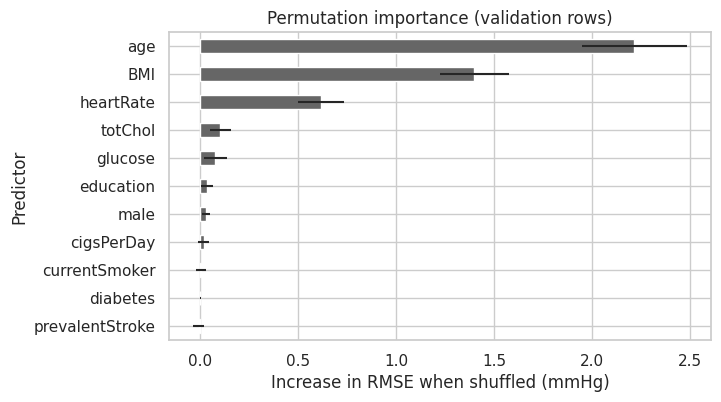

In [77]:
fig, ax = plt.subplots(figsize=(7, 4))
importance["mean_rmse_increase"][::-1].plot.barh(xerr=importance["sd"][::-1], ax=ax, color="0.4")
ax.set_title("Permutation importance (validation rows)")
ax.set_xlabel("Increase in RMSE when shuffled (mmHg)")
ax.set_ylabel("Predictor")
plt.show()

**🔎 What each line does**

- `[::-1]`  →  reverses the order so the largest bar is at the top
- `.plot.barh(xerr=`  →  horizontal bars; `xerr` draws the spread as error bars
- `ax.set_title`  →  title
- `ax.set_xlabel`  →  x label with unit
- `ax.set_ylabel`  →  y label

**👀 What you should see:** a long bar for age, a medium one for BMI, short bars for the rest.

### ✏️ TRY · Exercise 4.7 · Rank the predictors

From `importance`, store `top3` (the three predictor names with the largest mean increase, most important first, as a list) and `n_zero_ish` (how many predictors have a mean increase below 0.05 mmHg).

**Result variable(s):** `top3`, `n_zero_ish`

In [81]:
# [Exercise 4.7]
top3 = list(importance.index[:3])       # list(importance.index[:3])
n_zero_ish = int((importance["mean_rmse_increase"] <0.05).sum())   # int((importance["mean_rmse_increase"] < 0.05).sum())
print(top3, n_zero_ish)

['age', 'BMI', 'heartRate'] 6


In [82]:
check("4.7")   # 🎯 run this cell to check your answer

✅ `top3`: correct!
✅ `n_zero_ish`: correct!


### 💬 INTERPRET · Question 4.6 · What does importance mean here?

Name the most important predictors and explain why 'age is the most important predictor' does not mean 'age causes blood pressure to rise'. Why might two correlated predictors each look less important than they are?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [83]:
# [Question 4.6]
answer_4_6 = """Age is the most important predictor (2.213), followed by BMI (1.398) and heart rate (0.617), because disrupting these variables causes the largest increase in prediction error.
However, age being the most important predictor does not mean it causes blood pressure to rise, because predictive importance measures association with the outcome, not causation, and other factors may influence the relationship.
Two correlated predictors may each appear less important because they share similar information, allowing the model to rely on one when the other is disrupted.

"""

In [84]:
check("Q4.6")   # 🎯 run this cell to check your answer

📝 answer saved (84 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.6

A predictor's permutation importance is near zero. The safest conclusion is:

- **A.** It has no causal effect on sysBP
- **B.** This model barely relies on it for prediction
- **C.** It should be deleted from the dataset
- **D.** It is missing at random

In [85]:
# [Knowledge check 4.6]
kc_4_6 = "B"   # type "A", "B", "C" or "D"

In [86]:
check("K4.6")   # 🎯 run this cell to check your answer

✅ `kc_4_6`: correct!


---
## Part 7 · Error analysis on validation rows
*About 30 min · Research question(s): RQ12*

### 📘 LEARN · Where does the model go wrong?

One RMSE hides *who* is badly estimated. We look at predicted versus observed values, **residuals** (observed minus predicted) and errors by group. Define groups **before** looking at results, with enough rows to be meaningful. Large differences are a prompt for investigation, not a verdict.

### ▶️ SEE · Step 1: a table of errors

We add predictions, residuals, absolute errors and age bands to a copy of the validation rows.

In [87]:
val_pred = ridge.predict(X_val)
errors = val.assign(pred=val_pred, resid=y_val - val_pred, abs_err=(y_val - val_pred).abs())
errors["age_band"] = pd.cut(errors["age"], [0, 45, 55, 65, 100], labels=["<45", "45-54", "55-64", "65+"], right=False)
print(errors[["sysBP", "pred", "resid"]].head(3).round(1))

      sysBP   pred  resid
1554  164.0  134.7   29.3
1035  111.0  112.5   -1.5
2516  113.0  120.2   -7.2


**🔎 What each line does**

- `val_pred = ridge.predict(X_val)`  →  the model's predictions for the validation rows
- `errors = val.assign(`  →  adds new columns to a copy of val
- `resid=y_val - val_pred`  →  observed minus predicted (positive = the model guessed too low)
- `abs_err=`  →  size of the miss, ignoring direction
- `pd.cut(errors["age"], [0, 45, 55, 65, 100]`  →  cuts age into four bands; `right=False` includes the lower edge

**👀 What you should see:** three rows with observed, predicted and residual values.

### ▶️ SEE · Step 2: predicted versus observed

If predictions were perfect the dots would lie on the dashed diagonal.

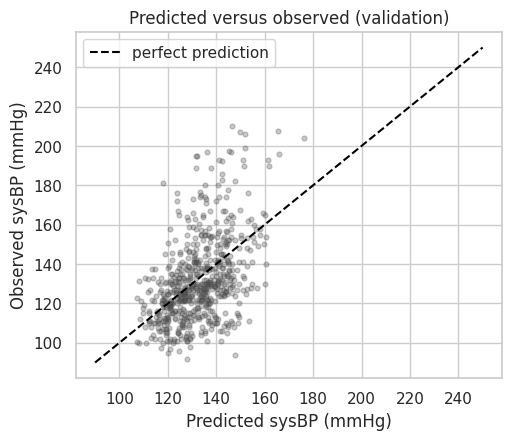

In [88]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(val_pred, y_val, alpha=0.3, s=12, color="0.3")
ax.plot([90, 250], [90, 250], color="black", linestyle="--", label="perfect prediction")
ax.set_title("Predicted versus observed (validation)")
ax.set_xlabel("Predicted sysBP (mmHg)")
ax.set_ylabel("Observed sysBP (mmHg)")
ax.legend()
plt.show()

**🔎 What each line does**

- `ax.scatter(val_pred, y_val`  →  one dot per person
- `ax.plot([90, 250], [90, 250]`  →  the diagonal where predicted equals observed
- `ax.legend()`  →  explains the line

**👀 What you should see:** a cloud flatter than the diagonal: high observed values sit far above their predictions.

### ▶️ SEE · Step 3: error by age band

Count and mean absolute error in each band.

In [89]:
print(errors.groupby("age_band", observed=True)["abs_err"].agg(["count", "mean"]).round(2))

          count   mean
age_band              
<45         219  11.63
45-54       212  13.69
55-64       174  17.62
65+          31  19.13


**👀 What you should see:** the mean error rises with age, from about 11.6 in the youngest band to about 19.1 in the oldest.

### ✏️ TRY · Exercise 4.8 · Errors for high and low blood pressure

Using `errors`: store `mae_high` (mean `abs_err` for rows with observed `sysBP` of 140 or more), `mae_normal` (the same for sysBP below 140) and `bias_high` (mean `resid` in the high group). A positive bias means the model under-estimates the high group.

**Result variable(s):** `mae_high`, `mae_normal`, `bias_high`

In [92]:
# [Exercise 4.8]
high = errors["sysBP"] >= 140        # True for the high-blood-pressure rows
mae_high = errors.loc[high, "abs_err"].mean()    # errors.loc[high, "abs_err"].mean()
mae_normal = errors.loc[~high, "abs_err"].mean()   # errors.loc[~high, "abs_err"].mean()   (~ means NOT)
bias_high = errors.loc[high, "resid"].mean()    # errors.loc[high, "resid"].mean()
print(mae_high, mae_normal, bias_high)

20.505239985311693 11.957868991395026 19.061814358652896


In [93]:
check("4.8")   # 🎯 run this cell to check your answer

✅ `mae_high`: correct!
✅ `mae_normal`: correct!
✅ `bias_high`: correct!


### 🔍 ANALYZE · Question 4.7 · Who is poorly estimated?

Describe the predicted-versus-observed plot and the Exercise 4.8 results. Why do models like this under-estimate the highest blood pressures, and why does that matter for flagging people with high blood pressure?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [94]:
# [Question 4.7]
answer_4_7 = """The plot shows that predictions are clustered around the average blood pressure, with substantial scatter around the perfect prediction line, while the Exercise 4.8 results (RMSE = 18.914, MAE = 14.351, R² = 0.215) indicate limited predictive accuracy.
The model underestimates the highest blood pressures because predictions tend to move towards the average when extreme values are difficult to capture, which matters because people with dangerously high blood pressure may be incorrectly classified as having lower readings and therefore go unnoticed.

"""

In [95]:
check("Q4.7")   # 🎯 run this cell to check your answer

📝 answer saved (81 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.7

A positive mean residual (observed minus predicted) for a group means the model:

- **A.** Under-estimates that group on average
- **B.** Over-estimates that group
- **C.** Is perfect for that group
- **D.** Has no data for that group

In [96]:
# [Knowledge check 4.7]
kc_4_7 = "A"   # type "A", "B", "C" or "D"

In [97]:
check("K4.7")   # 🎯 run this cell to check your answer

✅ `kc_4_7`: correct!


---
## Part 8 · Sensitivity analysis: adding BPMeds
*About 20 min · Research question(s): RQ10, RQ12*

### 📘 LEARN · A different question

`BPMeds` is **excluded** from the primary model: people are treated *because* their blood pressure is high, so treatment is entangled with the outcome (confounding by indication). Adding it may raise the score, but the model then answers a different question ("given known treatment, what is the reading?"). We report it only as a clearly labelled **sensitivity analysis**.

### ▶️ SEE · The sensitivity model (not the primary model)

Same recipe as before, with one extra yes/no column.

In [98]:
sens_features = FEATURES + ["BPMeds"]
sens_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), NUM),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
    ("bin", SimpleImputer(strategy="most_frequent"), BIN + ["BPMeds"])])
sens_model = Pipeline([("prep", sens_prep), ("model", Ridge(alpha=10))]).fit(train[sens_features], y_train)   # SENSITIVITY ONLY
sens_scores = evaluate(sens_model, val[sens_features], y_val)

**🔎 What each line does**

- `sens_features = FEATURES + ["BPMeds"]`  →  the usual 11 features plus BPMeds
- `("num", Pipeline(`  →  numeric recipe as before
- `("cat", Pipeline(`  →  category recipe as before
- `BIN + ["BPMeds"]`  →  BPMeds joins the yes/no columns
- `Ridge(alpha=10)`  →  the same model as the primary one
- `# SENSITIVITY ONLY`  →  a reminder that this is not the main result
- `evaluate(sens_model`  →  the three validation metrics

**👀 What you should see:** nothing printed.

### ▶️ SEE · Compare with the primary model

In [99]:
print("Primary Ridge:", {k: round(v, 3) for k, v in evaluate(ridge, X_val, y_val).items()})
print("With BPMeds  :", {k: round(v, 3) for k, v in sens_scores.items()})

Primary Ridge: {'RMSE': 18.878, 'MAE': 14.323, 'R2': 0.218}
With BPMeds  : {'RMSE': 18.771, 'MAE': 14.239, 'R2': 0.227}


**👀 What you should see:** RMSE falls by only about 0.1 mmHg (R squared 0.218 to 0.227).

### ✏️ TRY · Exercise 4.9 · Size of the BPMeds effect on the score

Store `rmse_primary` (RMSE of `ridge` on validation), `rmse_with_bpmeds` (from `sens_scores`) and `rmse_change` (primary minus with-BPMeds; positive means improvement).

**Result variable(s):** `rmse_primary`, `rmse_with_bpmeds`, `rmse_change`

In [100]:
# [Exercise 4.9]
rmse_primary = evaluate(ridge, X_val, y_val)["RMSE"]       # evaluate(ridge, X_val, y_val)["RMSE"]
rmse_with_bpmeds = sens_scores["RMSE"]   # sens_scores["RMSE"]
rmse_change = rmse_primary - rmse_with_bpmeds # rmse_primary - rmse_with_bpmeds
print(rmse_primary, rmse_with_bpmeds, rmse_change)

18.878225328858836 18.771418227443043 0.10680710141579297


In [101]:
check("4.9")   # 🎯 run this cell to check your answer

✅ `rmse_primary`: correct!
✅ `rmse_with_bpmeds`: correct!
✅ `rmse_change`: correct!


### 💬 INTERPRET · Question 4.8 · Why keep BPMeds out of the primary model?

BPMeds slightly improves the validation error. Explain why we still keep it out, and what question the sensitivity model answers instead.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [102]:
# [Question 4.8]
answer_4_8 = """We keep BPMeds out of the primary model because medication status may reflect previous blood pressure diagnosis or treatment decisions and may not be available at the time of prediction, potentially introducing information leakage.
The sensitivity model answers a different question: how much does predictive performance change when information about blood pressure medication use is included as a predictor?

"""

In [103]:
check("Q4.8")   # 🎯 run this cell to check your answer

📝 answer saved (59 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.8

A sensitivity analysis is:

- **A.** An extra analysis that shows whether conclusions change under another reasonable choice
- **B.** The main result
- **C.** A way to improve the test score
- **D.** A type of imputation

In [104]:
# [Knowledge check 4.8]
kc_4_8 = "A"   # type "A", "B", "C" or "D"

In [105]:
check("K4.8")   # 🎯 run this cell to check your answer

✅ `kc_4_8`: correct!


---
## Part 9 · Final evaluation on the test set (once)
*About 30 min · Research question(s): RQ10, RQ11, RQ12*

### 📘 LEARN · The only time we look at the test set

All decisions are finished. We **freeze** the model (Ridge, alpha = 10: near-best on validation, simplest and most interpretable), refit it on **training + validation** rows (more data, same settings) and score it on the test rows **once**. We do not change anything afterwards, whatever the result. Subgroup errors are reported **only now**, with group sizes.

### ▶️ SEE · Final refit and the single test evaluation

Run this cell once; do not tweak the model based on what it prints.

In [106]:
final_model = make_model(Ridge(alpha=10)).fit(train_val[FEATURES], train_val[TARGET])
X_test, y_test = test[FEATURES], test[TARGET]
final_scores = evaluate(final_model, X_test, y_test)
print("FINAL TEST RESULT:", {k: round(v, 3) for k, v in final_scores.items()})

FINAL TEST RESULT: {'RMSE': 19.006, 'MAE': 14.097, 'R2': 0.269}


**👀 What you should see:** RMSE about 19.0 and R squared about 0.27.

### ✏️ TRY · Exercise 4.10 · Report the test result

Store `test_rmse`, `test_mae` and `test_r2` from `final_scores`, and `generalisation_gap` = `test_rmse` minus the validation RMSE of `ridge`. Do not refit or change the model.

**Result variable(s):** `test_rmse`, `test_mae`, `test_r2`, `generalisation_gap`

In [108]:
# [Exercise 4.10]
test_rmse = final_scores["RMSE"]          # final_scores["RMSE"]
test_mae = final_scores["MAE"]         # final_scores["MAE"]
test_r2 = final_scores["R2"]              # final_scores["R2"]
generalisation_gap = test_rmse - evaluate(ridge, X_val, y_val)["RMSE"]   # test_rmse - evaluate(ridge, X_val, y_val)["RMSE"]
print(test_rmse, test_mae, test_r2, generalisation_gap)

19.005991461199315 14.096931707286092 0.269129769054415 0.1277661323404793


In [109]:
check("4.10")   # 🎯 run this cell to check your answer

✅ `test_rmse`: correct!
✅ `test_mae`: correct!
✅ `test_r2`: correct!
✅ `generalisation_gap`: correct!


### ▶️ SEE · Subgroup report (final test predictions only)

RMSE and bias by sex and age band, with group sizes.

In [123]:
test_report = test.assign(pred=final_model.predict(X_test))
test_report["resid"] = test_report["sysBP"] - test_report["pred"]
test_report["age_band"] = pd.cut(test_report["age"], [0, 45, 55, 65, 100], labels=["<45", "45-54", "55-64", "65+"], right=False)
test_report["sex"] = np.where(test_report["male"] == 1, "male", "female")
for col in ["sex", "age_band"]:
    g = test_report.groupby(col, observed=True)["resid"]
    print(pd.DataFrame({"n": g.size(), "RMSE": g.apply(lambda r: (r ** 2).mean() ** 0.5), "bias": g.mean()}).round(2))

          n   RMSE  bias
sex                     
female  367  19.70 -0.53
male    269  18.02  1.72
            n   RMSE  bias
age_band                  
<45       221  13.98  0.86
45-54     221  19.48  0.02
55-64     172  22.92 -0.16
65+        22  23.72  4.58


**🔎 What each line does**

- `test.assign(pred=`  →  copy of the test rows with predictions added
- `["resid"] = `  →  observed minus predicted
- `pd.cut(`  →  age bands as before
- `np.where(test_report["male"] == 1, "male", "female")`  →  a readable sex label
- `for col in ["sex", "age_band"]:`  →  repeat the report for each grouping
- `g.apply(lambda r: (r ** 2).mean() ** 0.5)`  →  RMSE within each group: square, average, square root
- `g.mean()`  →  bias within the group

**👀 What you should see:** two small tables: sex (2 rows) and age band (4 rows).

### 💬 INTERPRET · Question 4.9 · Report the final result honestly

Write a short results paragraph (4-6 sentences): what the model is, how it did on the test set compared with baseline and validation, whether performance is even across groups, and two limitations.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [124]:
# [Question 4.9]
answer_4_9 = """The final model was Ridge regression, which achieved an estimated test RMSE of approximately 19.01 mmHg, improving on the baseline RMSE of 21.36 mmHg and performing similarly to its validation RMSE of 18.88 mmHg.
 However, performance was not consistent across groups: males had lower prediction error than females (18.02 versus 19.70), while prediction error generally increased with age, reaching 23.72 among participants aged 65 and above.
 Two important limitations are the model's modest explanatory power (validation R² = 0.218) and the small sample size of the oldest age group (n = 22), which makes its performance estimate less reliable.
  The model also tends to underestimate the highest blood pressure readings, which could lead to high-risk individuals being overlooked.

"""

In [112]:
check("Q4.9")   # 🎯 run this cell to check your answer

📝 answer saved (118 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 4.9

After a disappointing test score, what is the **acceptable** next step?

- **A.** Re-tune the model until the test score improves
- **B.** Report the result as it is, with limitations, and plan a *new* evaluation
- **C.** Drop the test rows with the largest errors
- **D.** Swap the test and validation sets

In [117]:
# [Knowledge check 4.9]
kc_4_9 = "B"   # type "A", "B", "C" or "D"

In [118]:
check("K4.9")   # 🎯 run this cell to check your answer

✅ `kc_4_9`: correct!


---
## Part 10 · Putting it together
*About 20 min · Research question(s): RQ9-RQ12*

### 💬 INTERPRET · Question 4.10 · What did machine learning add?

In 5-6 sentences: Did non-linear models improve on the linear model? Which predictors mattered? Who is poorly estimated? Would you deploy this model for a clinical task, and why or why not?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [119]:
# [Question 4.10]
answer_4_10 = """Non-linear models such as random forest and gradient boosting did not improve on the linear Ridge model, which achieved better cross-validation performance with an RMSE of 18.95.
 Age was the most important predictor, followed by BMI and heart rate, based on their contribution to prediction error.
 Prediction was less accurate among older participants, particularly those aged 65 and above, and females also had slightly higher prediction errors than males.
 I would not deploy this model for clinical decision-making because its predictive accuracy is limited (R² = 0.218), and it tends to underestimate the highest blood pressure readings.
 Such errors could cause people with dangerously high blood pressure to be overlooked, so further model improvement and clinical validation are needed before practical use.

"""

In [120]:
check("Q4.10")   # 🎯 run this cell to check your answer

📝 answer saved (122 words). Your teacher will read it.


### 🔬 RESEARCH · Task 4.1 · Does a log-transformed target help?

Fit the carried-forward Ridge pipeline to `np.log(y_train)`, predict on validation, convert predictions back with `np.exp`, and compare the **validation RMSE in mmHg** with the untransformed Ridge. Does it help, and for which group?

Use the code cell for your analysis and summarise what you found, and what you could *not* conclude, in `research_4_1_summary`.

In [130]:
# [Research 4.1]


# Original target
model=ridge.fit(X_train, y_train)
pred = ridge.predict(X_val)

# Log-transformed target
ridge.fit(X_train, np.log(y_train))
pred_log = np.exp(ridge.predict(X_val))

# Compare RMSE
def rmse(y_true, y_pred):
    return ((y_true - y_pred) ** 2).mean() ** 0.5
print("Original:", rmse(y_val, pred))
print("Log-transformed:", rmse(y_val, pred_log))


# Compare predictions
results = pd.DataFrame({
    "actual": np.asarray(y_val),
    "original": pred,
    "log": pred_log
}, index=X_val.index)

# Create groups
results["sex"] = X_val["male"].map({0: "Female", 1: "Male"})

results["age_group"] = pd.cut(
    X_val["age"],
    bins=[-np.inf, 45, 55, 65, np.inf],
    labels=["<45", "45-54", "55-64", "65+"]
)

# Calculate RMSE for each group
group_results = []

for group in ["sex", "age_group"]:
    for name, data in results.groupby(group, observed=True):

        original_rmse = np.sqrt(
            np.mean((data["actual"] - data["original"])**2)
        )

        log_rmse = np.sqrt(
            np.mean((data["actual"] - data["log"])**2)
        )

        group_results.append({
            "Group": name,
            "Category": group,
            "Original_RMSE": original_rmse,
            "Log_RMSE": log_rmse,
            "Difference": log_rmse - original_rmse
        })

group_results = pd.DataFrame(group_results)

display(group_results.round(3))

# Store findings
improved = group_results[group_results["Difference"] < 0]["Group"].tolist()
worsened = group_results[group_results["Difference"] > 0]["Group"].tolist()





research_4_1_summary = """The log-transformed Ridge model slightly improved overall
validation RMSE from 18.878 to 18.791 mmHg. The greatest
improvement occurred among participants aged 65 and above,
followed by males and those aged 55-64. Performance was
almost unchanged among females and participants aged 45-54,
while predictions for those below 45 became slightly worse.
However, we cannot conclude that these improvements are
statistically significant or that they will generalise to
new data or improve clinical decision-making.

"""

Original: 18.878225328858836
Log-transformed: 18.790543156435454


,Group,Category,Original_RMSE,Log_RMSE,Difference
0,Female,sex,19.273,19.272,-0.001
1,Male,sex,18.329,18.118,-0.212
2,<45,age_group,15.584,15.596,0.012
3,45-54,age_group,18.762,18.752,-0.010
4,55-64,age_group,22.354,22.178,-0.176
5,65+,age_group,24.296,23.479,-0.817


In [131]:
check("R4.1")   # 🎯 run this cell to check your answer

📝 answer saved (72 words). Your teacher will read it.


---
### 📊 Your progress
Run this cell to see how many checks you have passed so far.

In [132]:
progress(4)

Notebook 4 progress
  Exercises passed:           9 of 10
  Knowledge checks correct:   9 of 9
  Written answers completed:  11 of 11  (your teacher reads these)
  Not checked yet: 4.1
  (Feedback only. Your instructor's marking is separate.)


---
### 📝 How this notebook is assessed
Your work is judged on **understanding**, not on matching a model answer line by line. Different correct approaches earn full credit.

| Criterion | Marks | Share |
|---|---|---|
| Correctness of analysis | 33.0 | 33% |
| Choice of statistical method | 1 | 1% |
| Interpretation | 29 | 29% |
| Code quality and reproducibility | 0 | 0% |
| Critical thinking and scientific reasoning | 36 | 36% |
| **Total** | **99.0** | |

The 🎯 checks give you feedback on the *result* you produce; the official marks come from your instructor, who also reads your written answers and research tasks.

### ✅ Before you submit
1. *Runtime → Restart session and run all* (or *Kernel → Restart & Run All*) finishes without errors.
2. Every `# TODO` is replaced and every `answer_...` variable is filled in.
3. Figures have a title, labelled axes and a legend when needed.
4. Save the notebook with your name in the filename.